# Мультиагентный ансамбль классических моделей: пошаговый разбор

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Msakhibullin24/A-multi-agent-ensemble-of-classical-machine-learning-models-/blob/main/notebooks/MAE_walkthrough.ipynb)

**М. М. Сахибуллин, Р. Х. Гильмеева**

Ноутбук показывает, как устроена модель MAE (Multi-Agent Ensemble) и как получены результаты исследования:

1. данные и постановка задачи;
2. агенты и их группы признаков;
3. обучение MAE на одном разбиении и сравнение с бустингом;
4. объяснение риска для конкретных учащихся (агент-интерпретатор);
5. итоговые результаты полного эксперимента (CV 5×5, поправка Холма).

Полный эксперимент долгий (~25 мин на 12 ядрах), поэтому здесь используются сохранённые результаты из `results/`. Пересчитать их можно в последнем разделе.

## 0. Подготовка окружения / Setup

In [1]:
import os, subprocess, sys
from pathlib import Path

if "google.colab" in sys.modules and not Path("src").exists():
    subprocess.run(["git", "clone", "-q", "https://github.com/Msakhibullin24/A-multi-agent-ensemble-of-classical-machine-learning-models-.git", "repo"], check=True)
    os.chdir("repo")
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-r", "requirements.txt"], check=True)
elif not Path("src").exists():  # запуск из папки notebooks/
    os.chdir("..")

sys.path.insert(0, "src")
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, display

pd.set_option("display.precision", 3)
print("Рабочая папка:", Path.cwd().name)

Рабочая папка: Sakhibullin_Science


## 1. Данные

Открытый набор [UCI Student Performance](https://doi.org/10.24432/C5TG7T) (CC BY 4.0). Он описывает учащихся двух португальских школ по математике и португальскому языку: анкета (семья, учёба, досуг) и оценки G1, G2, G3 по 20-балльной шкале.

**Группа риска:** итоговая оценка G3 < 10.

Признак `absences` (пропуски) исключён: в наборе это пропуски за весь год, то есть в момент прогноза он ещё неизвестен.

In [2]:
from experiment import GROUPS, load, scenario_groups

rows = []
for subject, name in [("mat", "Математика"), ("por", "Португальский")]:
    X, y, categorical = load(subject)
    rows.append({"Предмет": name, "Записей": len(y), "Группа риска": int(y.sum()),
                 "Доля риска, %": round(100 * y.mean(), 1), "Признаков (с G1)": X.shape[1]})
pd.DataFrame(rows)

,Предмет,Записей,Группа риска,"Доля риска, %",Признаков (с G1)
0,Математика,395,130,32.9,30
1,Португальский,649,100,15.4,30


Два сценария прогноза:
- **до начала обучения** — только анкета и учебная история (без оценок);
- **после первого периода** — добавляется оценка G1.

## 2. Агенты-эксперты

Каждый эксперт видит только свою группу признаков. «Общий» эксперт видит всё.

In [3]:
X, y, categorical = load("mat")
groups = scenario_groups("mid", X.columns)
pd.DataFrame({"Агент": list(groups), "Число признаков": [len(v) for v in groups.values()],
              "Признаки": [", ".join(v) if len(v) < 20 else "все" for v in groups.values()]})

,Агент,Число признаков,Признаки
0,Академический,8,"school, reason, studytime, failures, schoolsup..."
1,Семейно-социальный,13,"address, famsize, Pstatus, Medu, Fedu, Mjob, F..."
2,Поведенческий,9,"sex, age, activities, romantic, freetime, goou..."
3,Общий,30,все


Как агенты работают вместе:

- **Эксперт** перебирает шесть классических моделей (LR, SVM, kNN, NB, RF, GB) и оставляет лучшую по ROC AUC на внутренней кросс-валидации.
- **Координатор** даёт эксперту вес $w_i \cdot c_i(x)$:
  - $w_i = \max(\mathrm{AUC}_i - 0.5,\ \varepsilon)$ — общая компетентность;
  - $c_i(x)$ — точность эксперта на 25 самых похожих учащихся.
- **Итоговый риск:** $r(x) = \sum_i w_i c_i(x) p_i(x) / \sum_i w_i c_i(x)$.
- **Калибровщик** выбирает порог $\tau^*$, максимизирующий индекс Юдена $\mathrm{TPR} - \mathrm{FPR}$.
- **Интерпретатор** раскладывает $r(x)$ на вклады экспертов; их сумма равна $r(x)$.

![Архитектура](https://raw.githubusercontent.com/Msakhibullin24/A-multi-agent-ensemble-of-classical-machine-learning-models-/main/figures/fig1_architecture.png)

## 3. Обучение MAE на одном разбиении (≈1 мин)

In [4]:
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.metrics import roc_auc_score, balanced_accuracy_score, recall_score, precision_score
from mae import MultiAgentEnsemble, YoudenThreshold, base_models, make_preprocessor

X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.25, stratify=y, random_state=42)

mae = MultiAgentEnsemble(groups, categorical, local_k=25, seed=42).fit(X_tr, y_tr)
gb = make_pipeline(make_preprocessor(list(X.columns), categorical), base_models(42)["GB"])
models = {"MAE": mae, "GB (порог 0.5)": gb, "GB + тот же калибровщик": YoudenThreshold(gb, seed=42)}

rows = []
for name, m in models.items():
    if name != "MAE":
        m.fit(X_tr, y_tr)
    p = m.predict_proba(X_te)[:, 1]
    pred = m.predict(X_te)
    rows.append({"Модель": name, "ROC AUC": roc_auc_score(y_te, p),
                 "Сбаланс. точность": balanced_accuracy_score(y_te, pred),
                 "Полнота": recall_score(y_te, pred), "Точность": precision_score(y_te, pred)})
pd.DataFrame(rows).set_index("Модель")

,ROC AUC,Сбаланс. точность,Полнота,Точность
Модель,,,,
MAE,0.919,0.826,0.818,0.711
GB (порог 0.5),0.916,0.780,0.697,0.719
GB + тот же калибровщик,0.916,0.833,0.909,0.652


Какие модели выбрали агенты и какой порог подобрал калибровщик:

In [5]:
print(f"Порог калибровщика: {mae.threshold_:.2f}")
w = mae.agent_weights(X_te)
w = w / w.sum(1, keepdims=True)
pd.DataFrame({"Выбранная модель": [a.chosen for a in mae.agents_],
              "OOF ROC AUC": [a.auc for a in mae.agents_],
              "Средний вес в решении": w.mean(0)},
             index=pd.Index([a.name for a in mae.agents_], name="Агент"))

Порог калибровщика: 0.46


,Выбранная модель,OOF ROC AUC,Средний вес в решении
Агент,,,
Академический,LR,0.911,0.421
Семейно-социальный,LR,0.569,0.061
Поведенческий,RF,0.611,0.102
Общий,GB,0.906,0.417


На одном разбиении цифры шумные. Выводы делаются только по полному эксперименту (раздел 5).

## 4. Объяснение риска для педагога (агент-интерпретатор)

Для учащихся из тестовой части, отнесённых к группе риска, вклады агентов в сумме дают оценку риска:

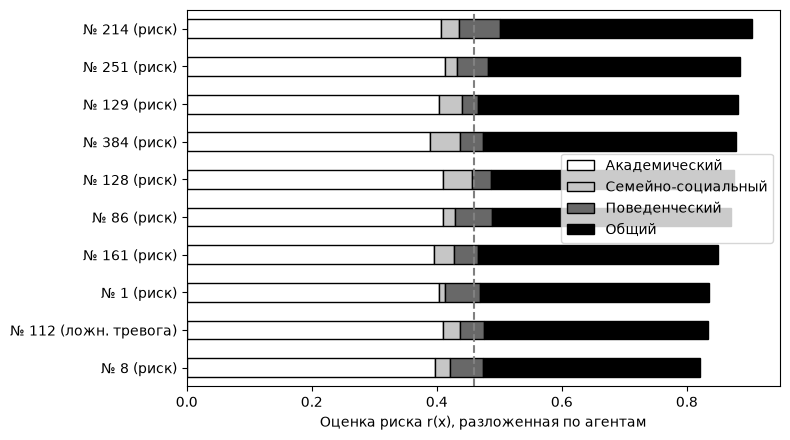

,Академический,Семейно-социальный,Поведенческий,Общий,Риск,Факт
213,0.41,0.03,0.07,0.40,0.90,1
250,0.41,0.02,0.05,0.40,0.88,1
128,0.40,0.04,0.02,0.42,0.88,1
383,0.39,0.05,0.04,0.40,0.88,1
127,0.41,0.05,0.03,0.39,0.88,1
85,0.41,0.02,0.06,0.38,0.87,1
160,0.40,0.03,0.04,0.38,0.85,1
0,0.40,0.01,0.06,0.37,0.84,1
111,0.41,0.03,0.04,0.36,0.83,0
7,0.40,0.02,0.05,0.35,0.82,1


In [6]:
risk = mae.predict_proba(X_te)[:, 1]
contrib = pd.DataFrame(mae.explain(X_te), index=X_te.index)
flagged = contrib[risk >= mae.threshold_].assign(Риск=risk[risk >= mae.threshold_],
                                                  Факт=y_te[risk >= mae.threshold_])
top = flagged.sort_values("Риск", ascending=False).head(10)

ax = top[list(groups)].plot.barh(stacked=True, figsize=(8, 4.5), colormap="Greys", edgecolor="black")
ax.set_yticklabels([f"№ {i + 1} ({'риск' if f else 'ложн. тревога'})" for i, f in zip(top.index, top["Факт"])])
ax.invert_yaxis(); ax.set_xlabel("Оценка риска r(x), разложенная по агентам")
ax.axvline(mae.threshold_, ls="--", color="grey"); plt.tight_layout(); plt.show()
top.round(2)

Как это читать: если преобладает вклад «Академического» агента, первоочередная мера — предметная поддержка. Если заметен «Поведенческий» — работа куратора или психолога.

Ограничение: разложение структурное, а не причинное, и само по себе не отличает ложную тревогу от истинной.

## 5. Результаты полного эксперимента

25 разбиений (CV 5×5) × 4 задачи. Для сравнения взяты базовые модели, классические ансамбли и контрольные модели с тем же калибровщиком порога.

In [7]:
TASKS = {"mat_early": "Мат., до обучения", "mat_mid": "Мат., 1-й период",
         "por_early": "Порт., до обучения", "por_mid": "Порт., 1-й период"}
res = {t: pd.read_csv(f"results/{t}_metrics.csv").set_index("model") for t in TASKS}
tests = {t: pd.read_csv(f"results/{t}_tests.csv") for t in TASKS}

auc = pd.DataFrame({name: res[t]["ROC AUC"] for t, name in TASKS.items()})
auc = auc.drop(index=[m for m in auc.index if m.endswith("+ порог") and m != "Выбор из 6 + порог"
                      or m.startswith("MAE:")])
print("ROC AUC, среднее по 25 разбиениям:")
auc.round(3)

ROC AUC, среднее по 25 разбиениям:


,"Мат., до обучения","Мат., 1-й период","Порт., до обучения","Порт., 1-й период"
model,,,,
LR,0.687,0.922,0.785,0.929
kNN,0.632,0.845,0.780,0.866
NB,0.651,0.811,0.773,0.844
DT,0.609,0.900,0.804,0.895
SVM,0.657,0.903,0.820,0.929
RF,0.675,0.905,0.840,0.934
AdaBoost,0.659,0.918,0.810,0.943
GB,0.662,0.916,0.822,0.943
Voting (soft),0.674,0.914,0.834,0.938


In [8]:
calibrated = ["LR + порог", "RF + порог", "GB + порог", "Voting (soft) + порог",
              "Выбор из 6 + порог", "MAE (полная)"]
ba = pd.DataFrame({name: res[t].loc[calibrated, "Balanced Acc"] for t, name in TASKS.items()})
print("Сбалансированная точность при одинаковой калибровке порога:")
ba.round(3)

Сбалансированная точность при одинаковой калибровке порога:


,"Мат., до обучения","Мат., 1-й период","Порт., до обучения","Порт., 1-й период"
model,,,,
LR + порог,0.621,0.846,0.727,0.859
RF + порог,0.615,0.833,0.775,0.863
GB + порог,0.595,0.846,0.752,0.870
Voting (soft) + порог,0.614,0.827,0.764,0.860
Выбор из 6 + порог,0.611,0.847,0.763,0.867
MAE (полная),0.631,0.844,0.766,0.870


Значимые различия с MAE (скорректированный t-критерий, поправка Холма, p < 0,05). Положительное `diff` — MAE лучше:

In [9]:
sig = pd.concat([tests[t].assign(Задача=name) for t, name in TASKS.items()])
sig = sig[(sig.p_holm < 0.05) & ~sig.model.str.startswith("MAE")]
sig[["Задача", "model", "metric", "diff", "p_holm"]].reset_index(drop=True)

,Задача,model,metric,diff,p_holm
0,"Мат., до обучения",kNN,Balanced Acc,0.072,2.559e-02
1,"Мат., до обучения",kNN,F1,0.240,4.236e-04
2,"Мат., до обучения",kNN,F2,0.336,1.423e-05
3,"Мат., до обучения",SVM,ROC AUC,0.042,2.532e-02
4,"Мат., до обучения",SVM,F1,0.315,8.483e-04
...,...,...,...,...,...
60,"Порт., 1-й период",Voting (soft),Balanced Acc,0.066,2.483e-02
61,"Порт., 1-й период",Voting (soft),F2,0.110,3.358e-02
62,"Порт., 1-й период",Stacking,Balanced Acc,0.099,2.209e-04
63,"Порт., 1-й период",Stacking,Precision,-0.203,7.544e-03


**Итог:**
- По ROC AUC MAE на уровне лучших ансамблей (GB, RF): значимых различий с ними нет.
- С контрольными моделями, у которых тот же калибровщик, значимых различий по пороговым метрикам тоже нет.
- Значимые выигрыши — только над слабыми одиночными моделями и над моделями с порогом 0,5.
- Значимые проигрыши — по точности (precision): низкий порог даёт больше ложных тревог.

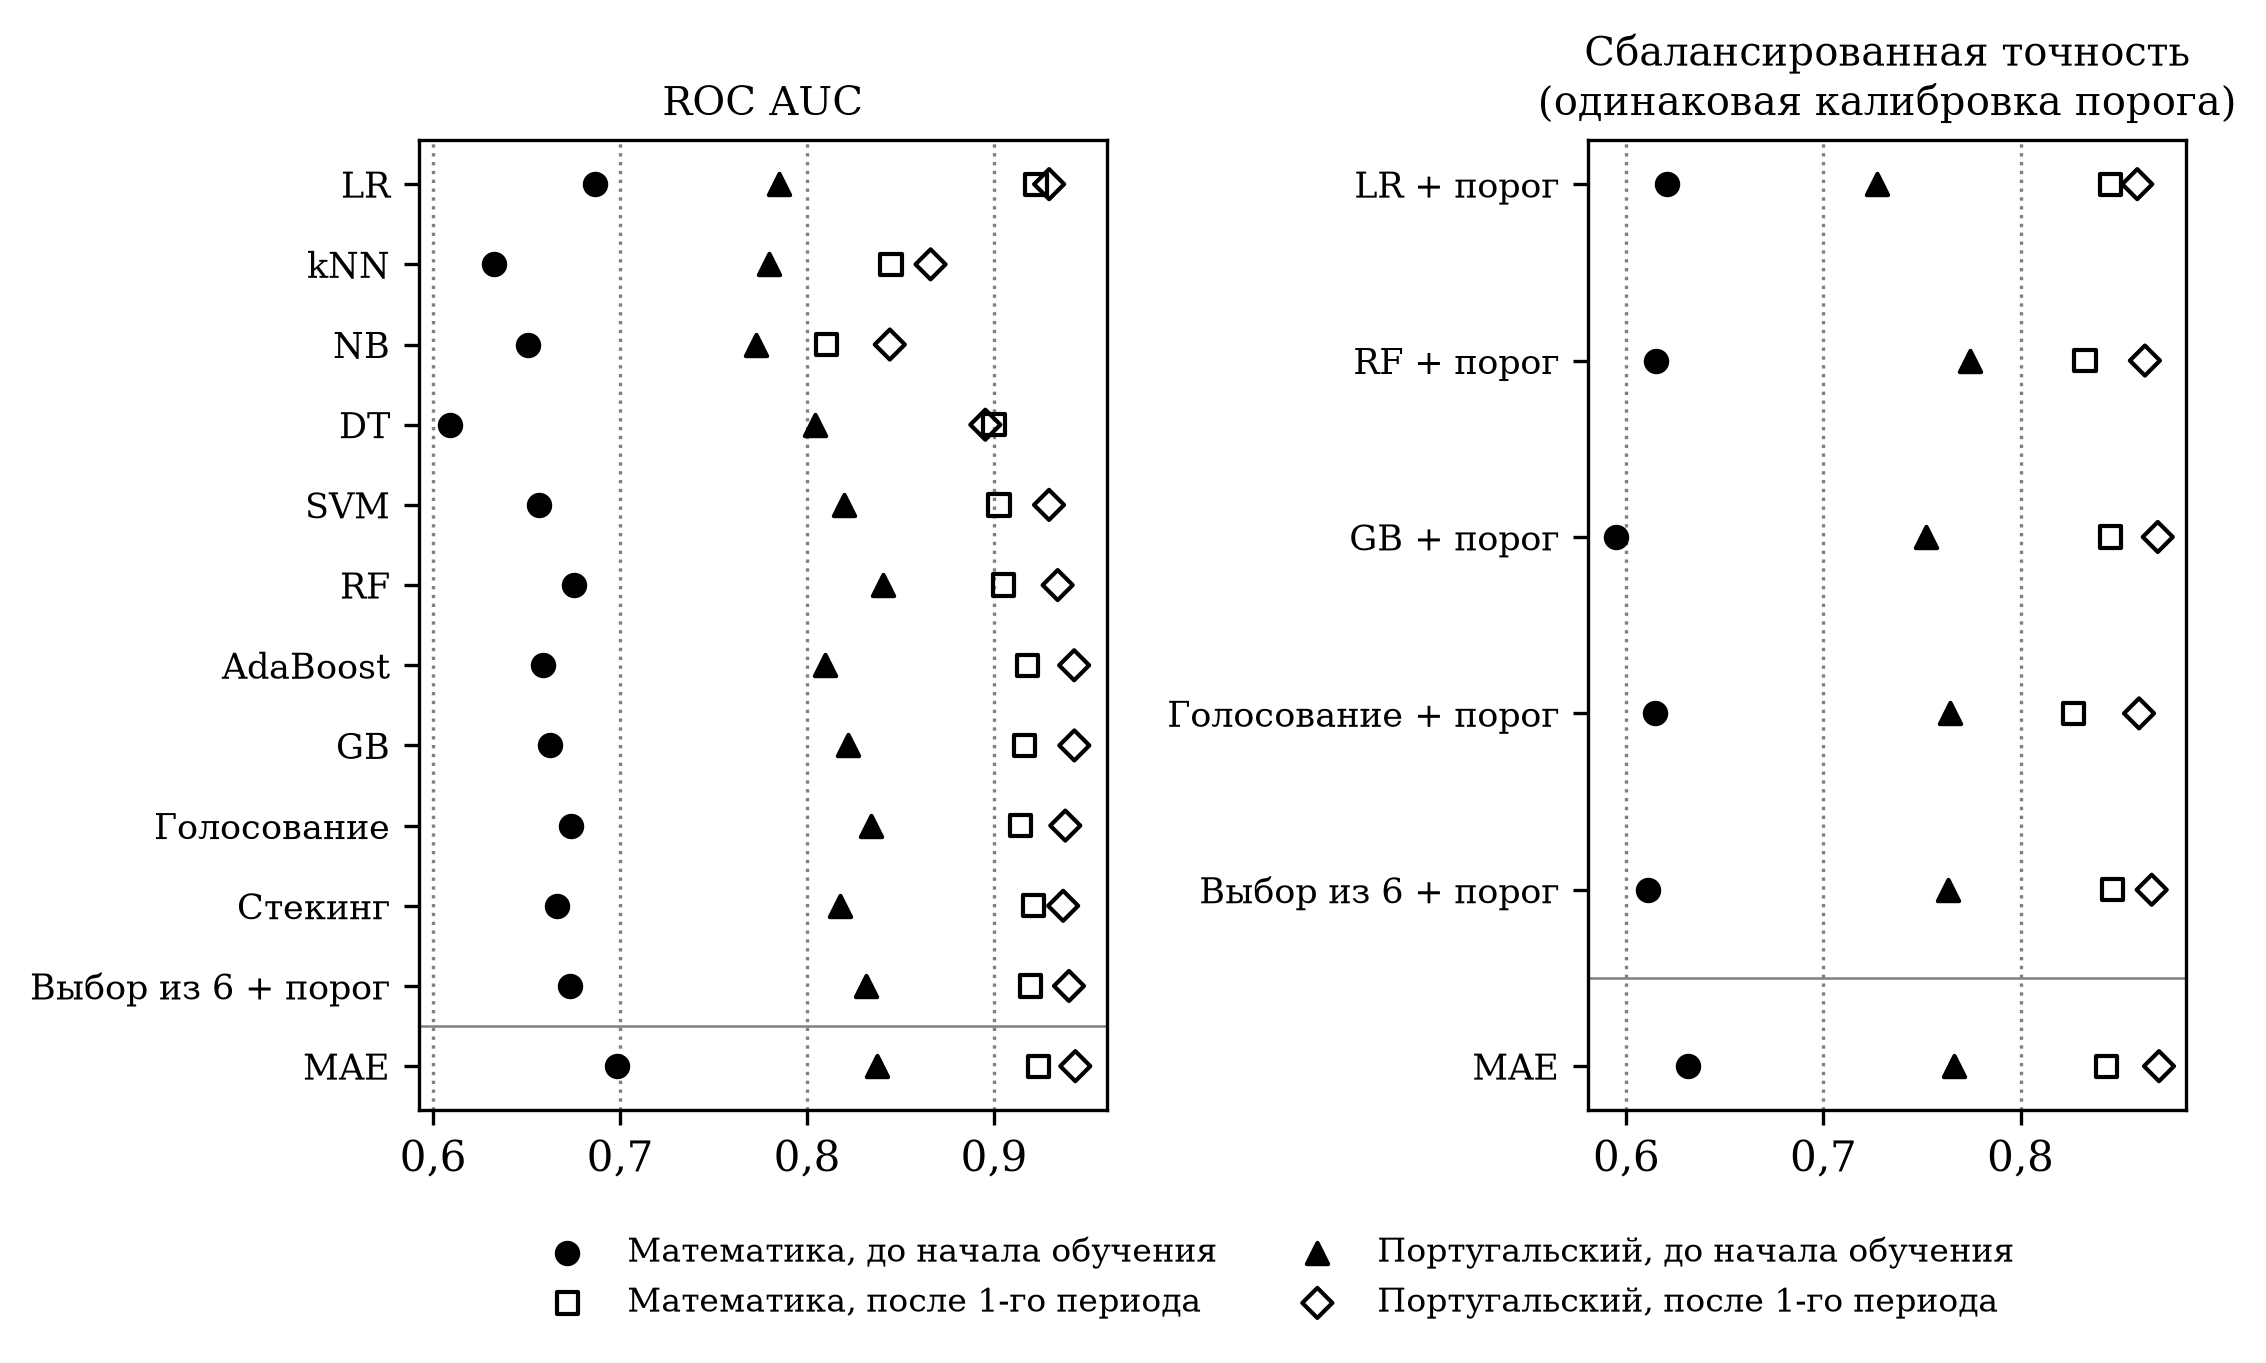

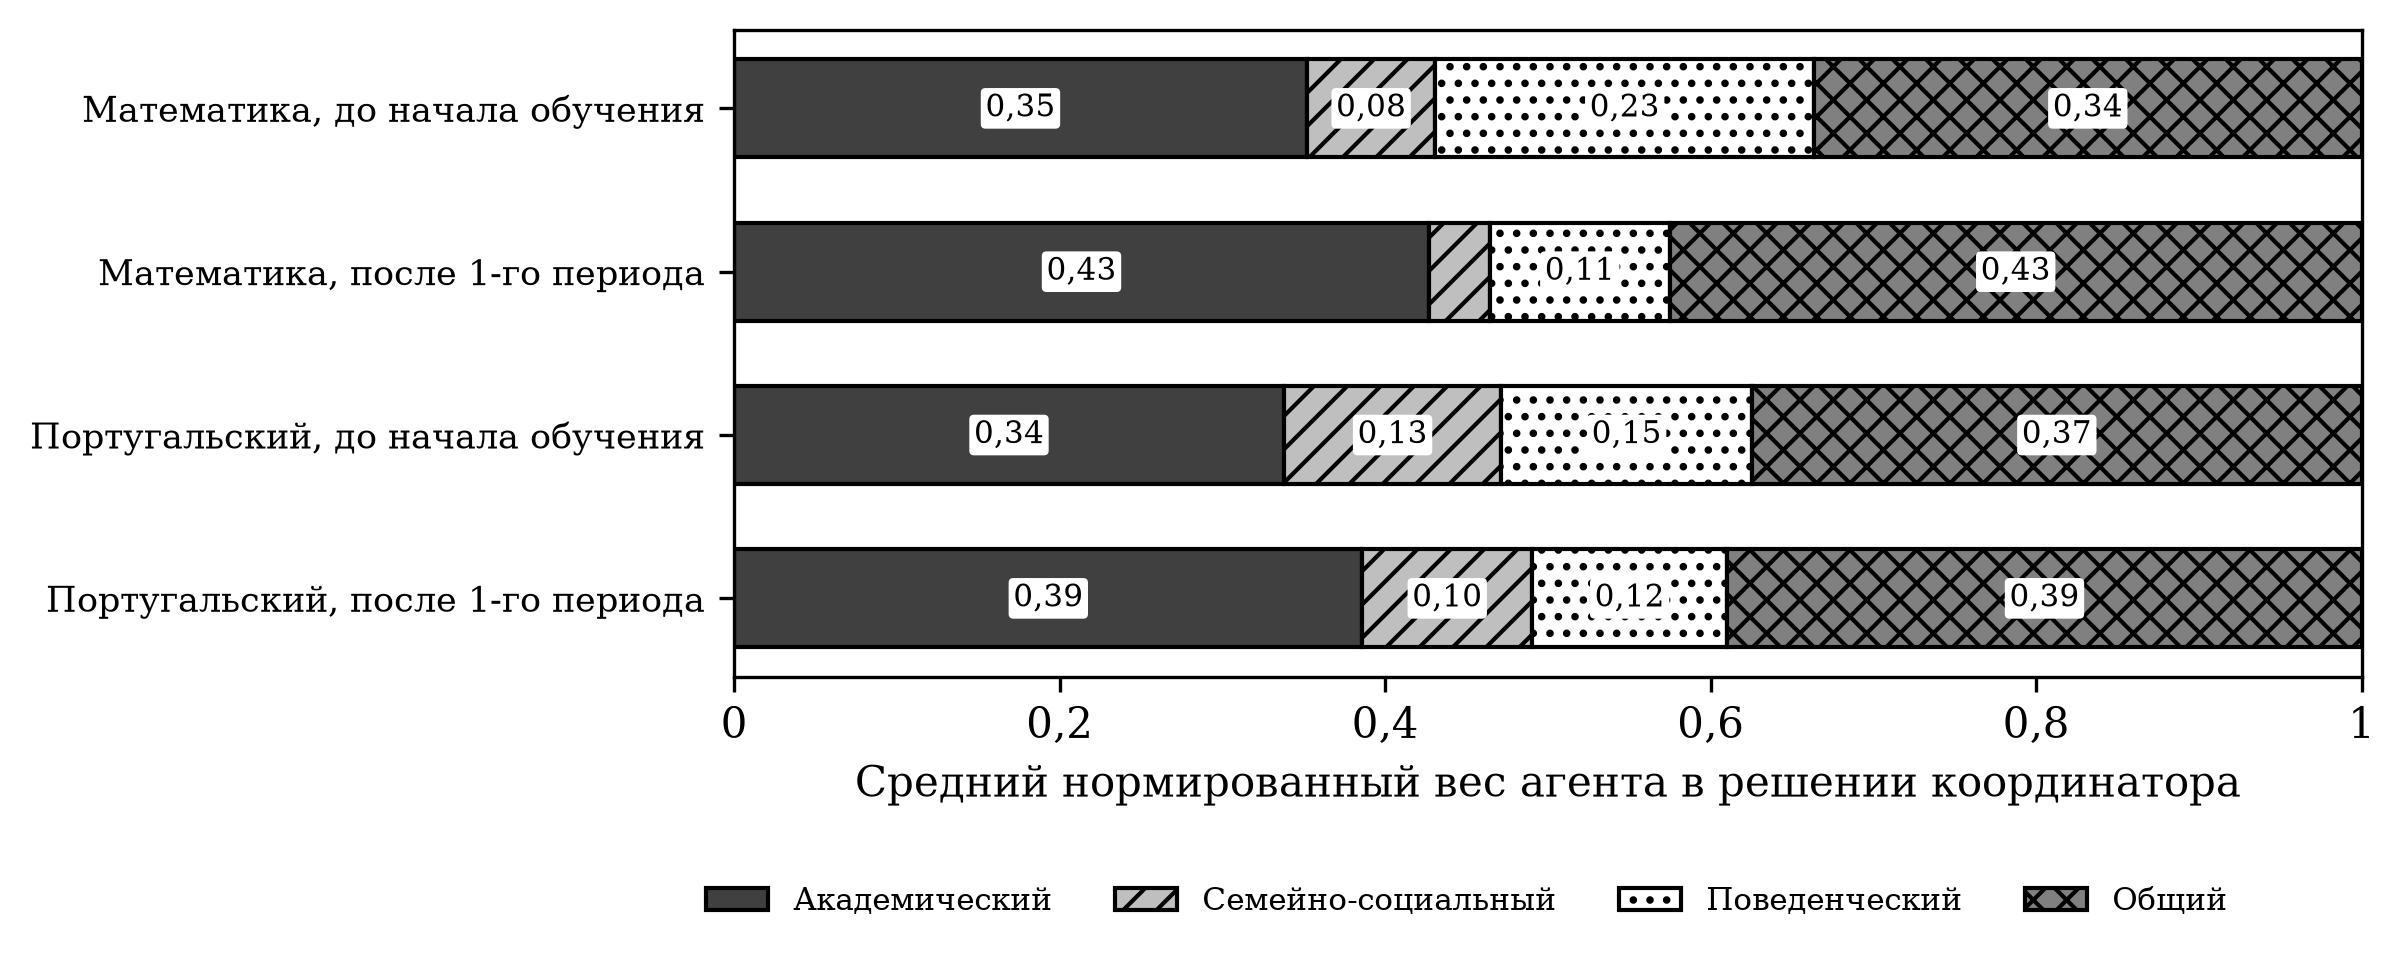

In [10]:
display(Image("figures/fig2_comparison.png", width=750))
display(Image("figures/fig3_agent_weights.png", width=750))

## 6. Полное воспроизведение

Запуск пересчитывает все результаты (~25 мин на 12 ядрах; на бесплатном Colab — несколько часов). Эксперимент возобновляемый: готовые задачи пропускаются, поэтому для пересчёта удалите `results/*_summary.json`.

In [11]:
RUN_FULL = False  # поставьте True, чтобы пересчитать всё
if RUN_FULL:
    subprocess.run([sys.executable, "src/experiment.py"], check=True)
    subprocess.run([sys.executable, "src/figures.py"], check=True)